# 02 — Baseline: MFCC statistics + logistic regression

Before training a CNN, I want a simple, cheap baseline. It answers two questions:
how hard is the task with hand-made features, and how much does the CNN in Phase 3 actually add?

The recipe is the classic one from before deep learning:
1. compute **MFCCs** for every frame of the note;
2. summarise each coefficient over time with its **mean and standard deviation** → one fixed-size vector per note;
3. fit a **logistic regression**.

In [1]:
import sys

import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "..")
from src.dataset import SR, load_notes
from src.features import HOP, MFCC_NAMES, load_mfcc_stats, mfcc

notes = load_notes()

## 1. What an MFCC is (recap from notebook 00)

Start from the log-mel spectrogram (128 bands per frame). For each frame, take a **DCT** (discrete cosine transform)
along the mel axis and keep the first 20 coefficients:

- coefficient 0 is roughly the overall loudness of the frame;
- the next few describe the broad shape of the spectrum (how energy is tilted from low to high frequencies, where the bumps are);
- the fine detail (individual harmonics) is in the higher coefficients, which are dropped.

So each frame goes from 128 numbers to 20, keeping mainly the **spectral envelope**: the "colour" of the sound rather
than its exact pitch. Below, the same two notes from notebook 00 with very different envelopes over time.

MFCC matrix shape (coefficients, frames): (20, 251)


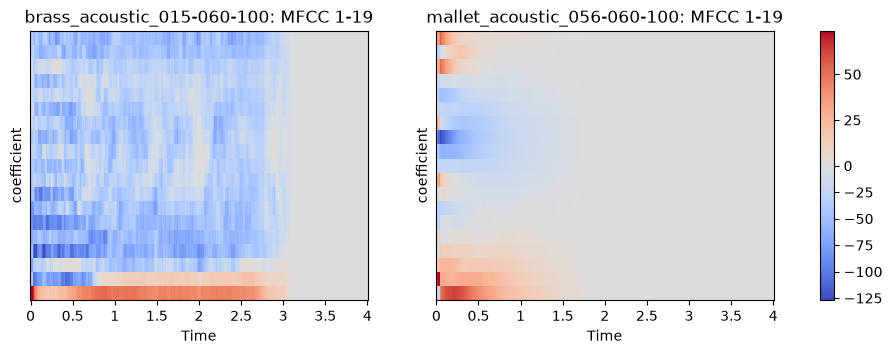

In [2]:
examples = ["brass_acoustic_015-060-100", "mallet_acoustic_056-060-100"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, name in zip(axes, examples):
    path = notes.loc[notes["note"] == name, "path"].item()
    m = mfcc(librosa.load(path, sr=None)[0])
    img = librosa.display.specshow(m[1:], sr=SR, hop_length=HOP, x_axis="time", ax=ax)  # c0 hidden: much larger scale
    ax.set(title=f"{name}: MFCC 1-19", ylabel="coefficient")
fig.colorbar(img, ax=axes)
print("MFCC matrix shape (coefficients, frames):", m.shape)

## 2. From a matrix to a vector

A classical model needs the same number of inputs for every note, so the time axis has to go.
For each of the 20 coefficients I keep its **mean** (the average spectral shape) and its **standard deviation**
(how much it changes during the note): 20 × 251 → **40 numbers**.

What this throws away: **the order of events in time**. The mean and std of a note played backwards are identical.
"Bright attack, then dark sustain" (brass) and "dark start, then bright" would look the same. This is the main thing
I expect the CNN, which sees the whole time × frequency image, to do better.

The features for all 16,774 notes are computed once by `python -m src.features` and cached in `data/features/`.

In [3]:
X = load_mfcc_stats(notes)
y = notes["family"].to_numpy()
train = (notes["split"] == "train").to_numpy()
X_train, y_train, X_test, y_test = X[train], y[train], X[~train], y[~train]
print(f"train: {X_train.shape}, test: {X_test.shape}")

pd.DataFrame(X_train, columns=MFCC_NAMES).describe().loc[["mean", "std", "min", "max"], ["mean_0", "mean_1", "mean_10", "std_0", "std_10"]].round(1)

train: (13339, 40), test: (3435, 40)


,mean_0,mean_1,mean_10,std_0,std_10
mean,-495.5,59.1,-1.2,81.3,7.9
std,115.1,62.0,13.6,42.6,4.1
min,-1007.8,-97.4,-50.1,5.4,0.4
max,-114.2,244.7,63.3,242.5,29.2


## 3. Model

**Logistic regression**: a linear model with one weight per feature per class, fast and with almost nothing to tune.
Two choices:

- **Standardise the features first.** As the table above shows, `mean_0` (loudness) is in the hundreds while other
  coefficients are around ±10. Without scaling, the regularisation would treat them very unevenly.
- **`class_weight="balanced"`.** Bass has ~6× more notes than vocal; without weighting, the model is pushed to
  favour the big classes.

I don't tune any hyperparameter (default `C=1.0`). There is no validation set, and tuning on the test set would make
the test score meaningless.

**Metric:** balanced accuracy = the average of the per-family recall. Chance level is 1/10 = **10%**.

In [4]:
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f"balanced accuracy  train: {balanced_accuracy_score(y_train, model.predict(X_train)):.3f}")
print(f"balanced accuracy  test:  {balanced_accuracy_score(y_test, pred):.3f}")
print(f"plain accuracy     test:  {accuracy_score(y_test, pred):.3f}")

balanced accuracy  train: 0.748
balanced accuracy  test:  0.188
plain accuracy     test:  0.180


In [5]:
report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
test_instrument = notes.loc[~train].groupby("family")["instrument"].first()
per_family = report.loc[sorted(set(y)), ["recall", "precision", "support"]].join(test_instrument.rename("test instrument"))
per_family.round(2)

,recall,precision,support,test instrument
bass,0.28,0.21,440.0,bass_synthetic_134
brass,0.46,0.39,285.0,brass_acoustic_046
flute,0.00,0.00,440.0,flute_synthetic_000
guitar,0.08,0.08,440.0,guitar_acoustic_014
keyboard,0.12,0.13,440.0,keyboard_electronic_002
mallet,0.00,0.00,220.0,mallet_acoustic_047
organ,0.85,0.25,305.0,organ_electronic_001
reed,0.09,0.32,215.0,reed_acoustic_011
string,0.00,0.00,210.0,string_acoustic_014
vocal,0.01,0.10,440.0,vocal_synthetic_003


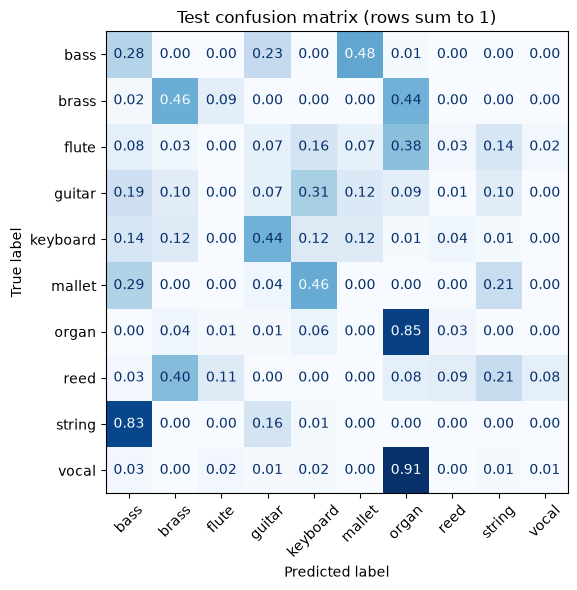

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize="true", values_format=".2f", cmap="Blues",
                                        xticks_rotation=45, colorbar=False, ax=ax)
ax.set(title="Test confusion matrix (rows sum to 1)")
plt.tight_layout()

### Reading the results

**Test balanced accuracy is 0.19**, a bit above chance (0.10). On the training set it's 0.75. So the model did learn
something, but most of it doesn't carry over to instruments it has never heard.

The errors aren't random, and several make physical sense:

- **mallet → keyboard** (46% of mallet notes) and **keyboard → guitar** (44%): all three are struck or plucked, with
  energy decaying after the attack. A piano is, physically, felt mallets hitting strings.
- **reed → brass** (40%): both are sustained wind instruments.
- **organ is the "default" for steady sounds.** Organ recall is 0.85, but its precision is only 0.25: 91% of vocal, 44% of
  brass and 38% of flute notes are called organ. After averaging over time, any steady, sustained tone looks like an organ.
- **string → bass** (83%) and **bass → mallet** (48%): not obvious to me why. Worth listening to these notes during the
  error analysis in Phase 4.
- **flute and vocal ≈ 0**, as expected from Phase 1: trained on the acoustic instrument, tested on the synthetic one.

## 4. What happens with a random split (the leakage from Phase 1, measured)

Phase 1 argued that splitting notes at random leaks instrument identity into the test set. Here is the same model,
same features, but with a random note-level split of the same size (stratified by family):

In [7]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y, test_size=(~train).mean(), stratify=y, random_state=0)
leaky = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(Xr_train, yr_train)

pd.DataFrame({
    "split": ["random notes (leaky)", "by instrument (Phase 1)"],
    "balanced accuracy (test)": [balanced_accuracy_score(yr_test, leaky.predict(Xr_test)), balanced_accuracy_score(y_test, pred)],
}).round(3)

,split,balanced accuracy (test)
0,random notes (leaky),0.602
1,by instrument (Phase 1),0.188


Same features, same model, same test size: **0.60 vs 0.19**. The gap comes entirely from the random test set containing
other notes of the training instruments. With a careless split, 0.60 is the number I would have reported, but it measures
"can you recognise these 53 instruments again", not "can you tell the family of an instrument you've never heard".

## Takeaways

- **The honest baseline is 0.19 balanced accuracy.** It's low, but it's the number the CNN has to beat.
- **The main bottleneck looks like the data, not the model.** The gap between train (0.75) and test (0.19) means the model
  fits the training instruments but can't generalise to new ones. With 43 training instruments (some families have only
  1 or 2), it sees very little of how instruments *within* a family differ.
- **The mean/std summary throws away the order of events in time.** The CNN in Phase 3 sees the full log-mel image, so it
  can use the shape of the envelope. It has the same data problem, though, so I don't expect a dramatic jump.
- **Per-family numbers are noisy.** Each one is measured on a single test instrument (see Phase 1).